# Relatório Visual: investimento e força de trabalho nas IFES (1996–2026)

Cada gráfico abaixo vem acompanhado de duas partes:

- **O fato**: o que os dados mostram naquele período.
- **O design**: por que aquele tipo de gráfico, paleta, limites de eixo e legenda foram a melhor escolha.

**Ressalva sobre os dados:** o CSV não informa se os valores financeiros estão em reais correntes ou deflacionados. Por isso, as comparações de valores entre anos distantes devem ser lidas com cuidado.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sb

df = pd.read_csv("dados_investimento_e_vagas_ifes.csv").sort_values('ano').reset_index(drop=True)

# Variação percentual ano a ano
df['var_assistencia_pct'] = df['investimento_assistencia_estudantil_bilhoes_brl'].pct_change() * 100
df['var_investimento_pct'] = df['investimento_total_ifes_bilhoes_brl'].pct_change() * 100
df['var_vagas_pct'] = df['num_vagas_estudantes'].pct_change() * 100

# Proporções de força de trabalho
df['estudantes_por_docente'] = df['num_vagas_estudantes'] / df['num_vagas_docente']
df['estudantes_por_tae'] = df['num_vagas_estudantes'] / df['num_vagas_tae']

# Períodos presidenciais
df['periodo'] = pd.cut(
    df['ano'],
    bins=[1994, 1998, 2002, 2006, 2010, 2014, 2018, 2022, 2026],
    labels=['1995-1998 (FHC)', '1999-2002 (FHC)', '2003-2006 (Lula)', '2007-2010 (Lula)',
            '2011-2014 (Dilma)', '2015-2018 (Dilma/Temer)', '2019-2022 (Bolsonaro)', '2023-2026 (Lula)']
)
resumo = df.groupby('periodo', observed=True).agg(
    assistencia_media=('investimento_assistencia_estudantil_bilhoes_brl', 'mean'),
    assistencia_soma=('investimento_assistencia_estudantil_bilhoes_brl', 'sum'),
    vagas_media=('num_vagas_estudantes', 'mean'),
    vagas_soma=('num_vagas_estudantes', 'sum'),
).reset_index()
resumo['assistencia_por_vaga'] = resumo['assistencia_soma'] * 1_000_000_000 / resumo['vagas_soma']
resumo['vagas_mil'] = resumo['vagas_media'] / 1000

## Figura 1: Evolução do investimento total

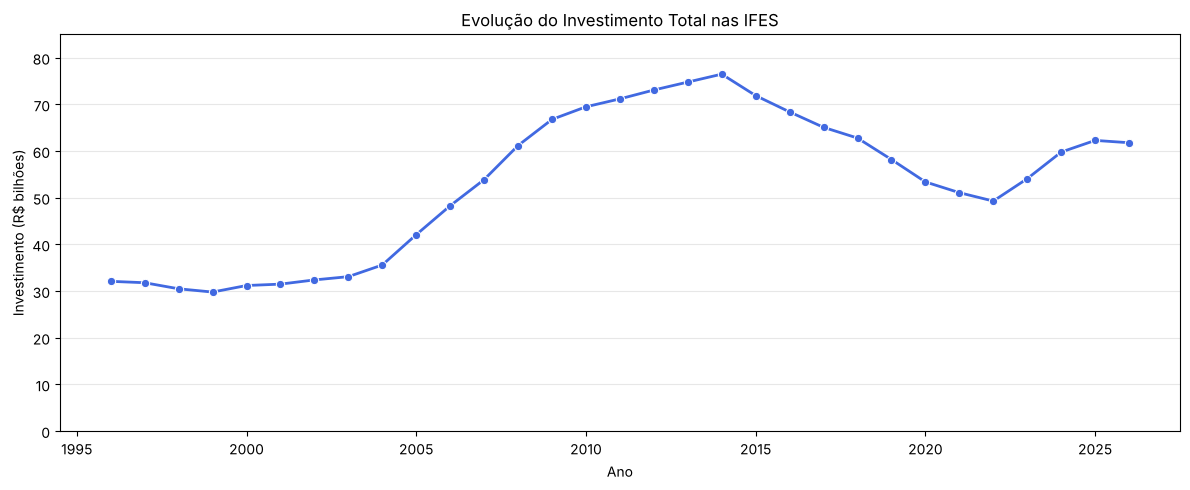

In [2]:
plt.figure(figsize=(12, 5))
sb.lineplot(data=df, x='ano', y='investimento_total_ifes_bilhoes_brl',
            marker='o', color='royalblue', linewidth=2)
plt.ylim(0, 85)
plt.title('Evolução do Investimento Total nas IFES')
plt.xlabel('Ano')
plt.ylabel('Investimento (R$ bilhões)')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

**O fato.** O investimento total saiu de R$ 32,1 bi em 1996 e chegou ao mínimo de R$ 29,8 bi em 1999. De 2004 a 2014 cresceu quase sem interrupção até o pico de R$ 76,5 bi (2,6 vezes o valor de 1999). A partir de 2015 houve oito anos seguidos de queda, até R$ 49,3 bi em 2022 (35,6% abaixo do pico). Depois disso o investimento voltou a subir e ficou em R$ 61,8 bi em 2026, ainda cerca de 19% abaixo de 2014.

**O design.** Os dados são anuais e contínuos, então um **gráfico de linhas com marcadores** deixa ver as fases de crescimento, queda e recuperação, e os marcadores preservam a leitura de cada ano. Foi feito **um gráfico por variável**, e não um eixo duplo, porque investimento (bilhões de reais) e vagas (milhões de estudantes) têm unidades e escalas incomparáveis. O **eixo y começa em zero** para que a queda pós-2014 seja lida na proporção real, sem exagero visual. Como há uma só série, não há legenda; o título e o rótulo do eixo (com a unidade, R$ bilhões) bastam.

## Figura 2: Evolução do número de vagas de estudantes

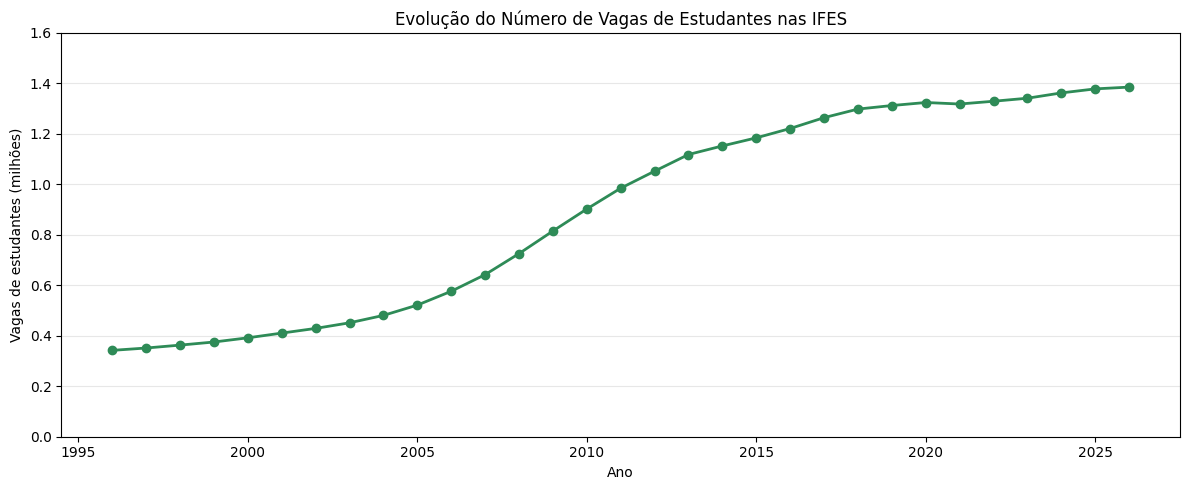

In [2]:
plt.figure(figsize=(12, 5))
plt.plot(df['ano'], df['num_vagas_estudantes'] / 1_000_000,
         marker='o', linewidth=2, color='seagreen')
plt.ylim(0, 1.6)
plt.title('Evolução do Número de Vagas de Estudantes nas IFES')
plt.xlabel('Ano')
plt.ylabel('Vagas de estudantes (milhões)')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

**O fato.** As vagas passaram de 342 mil em 1996 para 1,385 milhão em 2026, cerca de 4 vezes mais. O crescimento foi acelerado entre 2004 e 2013, quando as vagas foram de 481 mil para 1,118 milhão. Desde 2014 o ritmo desacelerou muito: de 1,152 milhão para 1,385 milhão em 2026 (+20%). O único recuo da série foi em 2021 (1,324 → 1,318 milhão).

**O design.** Também é uma **linha com marcadores**, pelos mesmos motivos da Figura 1, e com cor diferente (verde) para sinalizar que se trata de outra variável. O valor foi convertido para **milhões** para que o eixo fique com números curtos (0 a 1,6) em vez de sete dígitos. O eixo y começa em zero. A Figura 1 e esta lado a lado mostram um contraste importante: de 2014 a 2026 o investimento total caiu cerca de 19% enquanto as vagas cresceram cerca de 20%.

## Figura 3: Proporção de vagas de estudantes por docente e por TAE

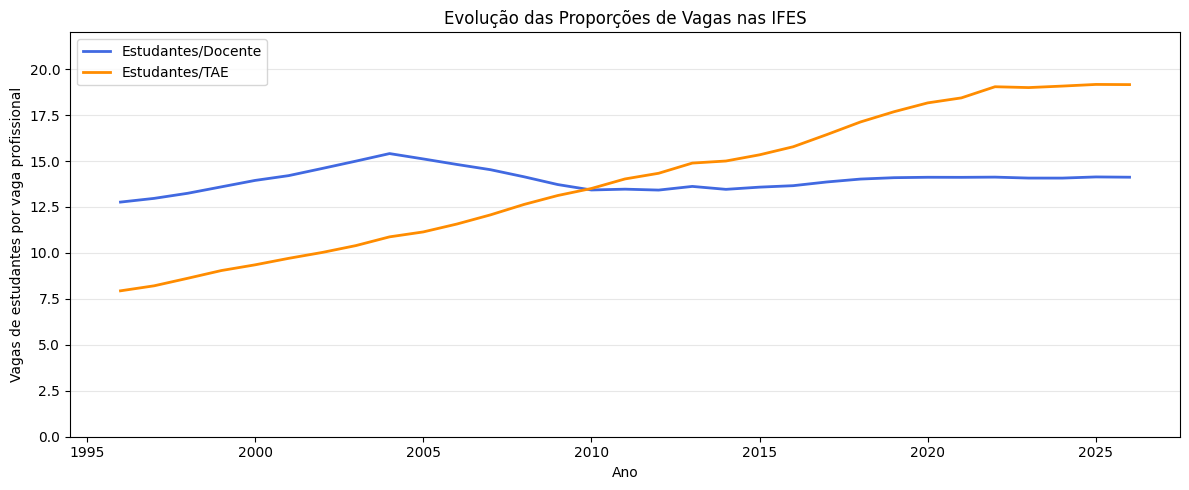

In [3]:
plt.figure(figsize=(12, 5))
plt.plot(df['ano'], df['estudantes_por_docente'], label='Estudantes/Docente', color='royalblue', linewidth=2)
plt.plot(df['ano'], df['estudantes_por_tae'], label='Estudantes/TAE', color='darkorange', linewidth=2)
plt.ylim(0, 22)
plt.xlabel('Ano')
plt.ylabel('Vagas de estudantes por vaga profissional')
plt.title('Evolução das Proporções de Vagas nas IFES')
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

**O fato.** A razão estudantes por docente variou pouco: 12,8 em 1996, pico de 15,4 em 2004, 13,4 em 2010 e 14,1 em 2026. Já a razão estudantes por TAE quase triplicou, de 7,9 em 1996 para 19,2 em 2025 (e se manteve em torno de 19 desde 2022). As duas linhas se cruzam entre 2009 e 2010: antes disso havia mais estudantes por docente do que por TAE, e depois a situação se inverteu. Em outras palavras, a expansão de vagas foi acompanhada por contratação de docentes em ritmo próximo, mas não de técnicos-administrativos.

**O design.** As duas razões têm **a mesma unidade** (vagas de estudantes por vaga profissional), então cabem no **mesmo gráfico de linhas**, o que permite ver diretamente quando se aproximam, se cruzam e se afastam. Foram usadas **duas cores contrastantes** (azul e laranja), seguindo a natureza qualitativa das duas séries (sem ordem entre elas), e a **legenda** nomeia cada linha. O eixo y começa em zero (limite em 22) para que a diferença de nível entre as razões seja lida sem distorção. Foram evitados marcadores para não poluir duas linhas que já são facilmente distinguíveis.

## Figura 4: Assistência estudantil e vagas por período presidencial

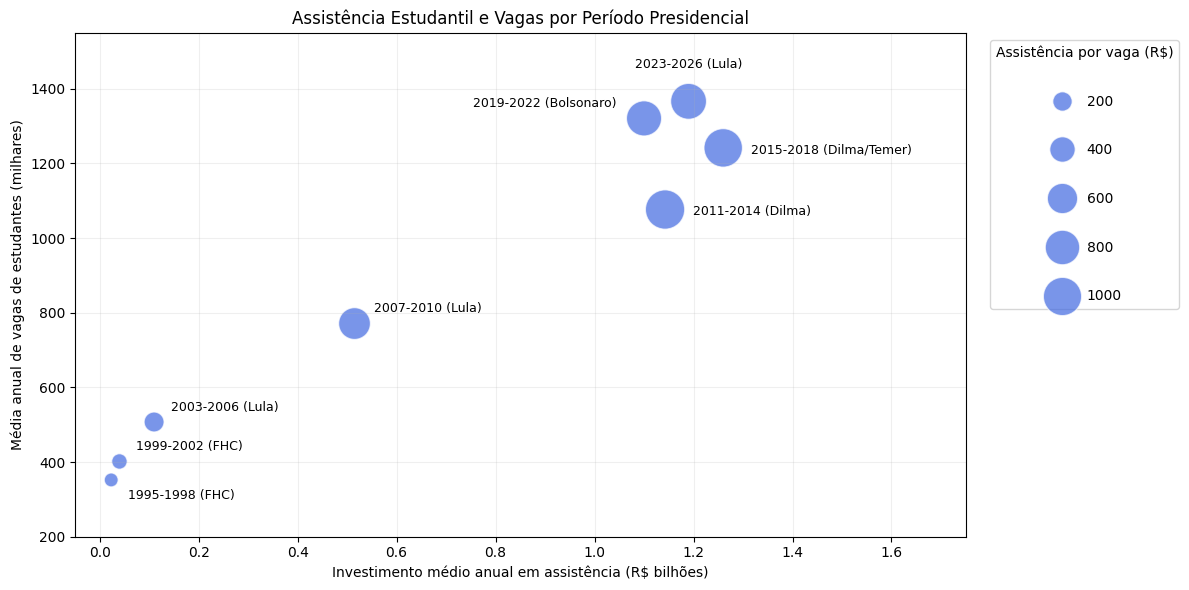

In [4]:
plt.figure(figsize=(12, 6))
ax = sb.scatterplot(
    data=resumo, x='assistencia_media', y='vagas_mil',
    size='assistencia_por_vaga', sizes=(100, 800),
    color='royalblue', alpha=0.7, edgecolor='white', legend='brief'
)
# deslocamento e alinhamento de cada rótulo, para evitar sobreposição
POS = {
    '1995-1998 (FHC)': ((12, -14), 'left'),
    '1999-2002 (FHC)': ((12, 8), 'left'),
    '2003-2006 (Lula)': ((12, 8), 'left'),
    '2007-2010 (Lula)': ((14, 8), 'left'),
    '2011-2014 (Dilma)': ((20, -4), 'left'),
    '2015-2018 (Dilma/Temer)': ((20, -4), 'left'),
    '2019-2022 (Bolsonaro)': ((-20, 8), 'right'),
    '2023-2026 (Lula)': ((0, 24), 'center'),
}
for _, l in resumo.iterrows():
    deslocamento, alinhamento = POS[str(l['periodo'])]
    plt.annotate(str(l['periodo']), (l['assistencia_media'], l['vagas_mil']),
                 xytext=deslocamento, textcoords='offset points',
                 ha=alinhamento, fontsize=9)

plt.title('Assistência Estudantil e Vagas por Período Presidencial')
plt.xlabel('Investimento médio anual em assistência (R$ bilhões)')
plt.ylabel('Média anual de vagas de estudantes (milhares)')
ax.legend(title='Assistência por vaga (R$)', bbox_to_anchor=(1.02, 1),
          loc='upper left', labelspacing=2.5)
plt.xlim(-0.05, 1.75)
plt.ylim(200, 1550)
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

**O fato.** A média anual de vagas cresce em todos os períodos, de 352 mil em 1995-1998 até 1,37 milhão em 2023-2026. O investimento médio anual em assistência estudantil acompanhou esse crescimento até 2015-2018 (de R$ 0,02 bi para R$ 1,26 bi), mas depois recuou para R$ 1,10 bi em 2019-2022 e voltou a R$ 1,19 bi em 2023-2026. A assistência por vaga teve pico de cerca de R$ 1.061 em 2011-2014 e desde então caiu: R$ 1.015, R$ 833 e R$ 871 nos períodos seguintes. Portanto, as vagas continuaram crescendo, mas a assistência por vaga voltou a ficar menor do que no auge.

**O design.** Escolhi o **gráfico de dispersão com bolhas** em vez do mapa de calor de correlação. Com apenas 8 períodos, uma matriz de correlação resumiria tudo em poucos números e esconderia a trajetória. O gráfico de bolhas mostra cada período como um ponto, com **duas variáveis nos eixos** (assistência média e vagas médias) e **a terceira no tamanho** (assistência por vaga), que responde exatamente à pergunta do enunciado: o investimento acompanhou proporcionalmente o aumento de vagas? Todos os pontos têm a mesma cor, já que cor não carrega informação aqui, e **rótulos diretos** identificam cada período. A legenda de tamanho está em R$ por vaga, fora da área de dados. Observação: embora a correlação anual entre as duas variáveis seja alta (cerca de 0,97), ela é puxada pela tendência de alta comum de 1996 a 2014 e não prova causalidade nem proporcionalidade.

## Figura 5: Anos críticos na assistência estudantil

In [5]:
# (variações já calculadas acima)
LIMITE_ESTAGNACAO = 1.0  # variação anual da assistência <= 1% conta como corte ou estagnação

anos_criticos = df.groupby('ano').filter(
    lambda g: (g['var_assistencia_pct'] <= LIMITE_ESTAGNACAO).all()
              and (g['var_vagas_pct'] > 0).all()
)
df['ano_critico'] = df['ano'].isin(anos_criticos['ano'])

# Agrupa anos críticos consecutivos em faixas (ex.: 2015-2020) para o sombreamento
bloco = (df['ano_critico'] != df['ano_critico'].shift()).cumsum()
faixas = (
    df[df['ano_critico']]
    .groupby(bloco[df['ano_critico']])['ano']
    .agg(['min', 'max'])
)

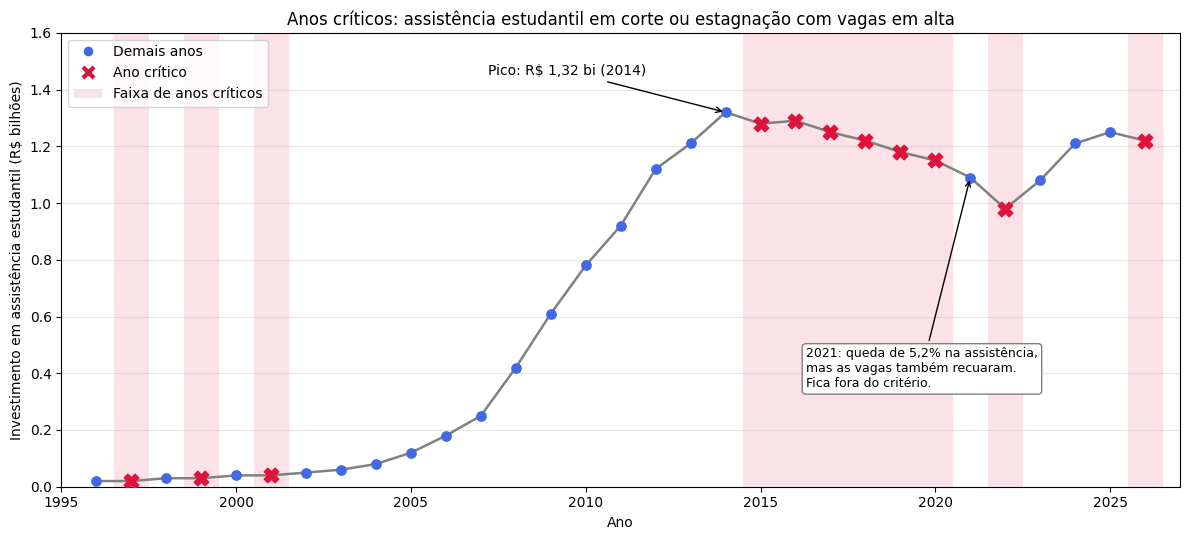

In [6]:
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

COR_CRITICO = 'crimson'
COR_NORMAL = 'royalblue'
col = 'investimento_assistencia_estudantil_bilhoes_brl'
normais = df[~df['ano_critico']]
criticos = df[df['ano_critico']]

fig, ax = plt.subplots(figsize=(12, 5.5))

# 1) sombreamento de fundo nas faixas críticas
for _, f in faixas.iterrows():
    ax.axvspan(f['min'] - 0.5, f['max'] + 0.5, color=COR_CRITICO, alpha=0.12, linewidth=0)

# 2) linha do tempo + marcadores (formato e cor diferentes nos anos críticos)
ax.plot(df['ano'], df[col], color='gray', linewidth=1.8, zorder=2)
ax.scatter(normais['ano'], normais[col], color=COR_NORMAL, s=45, zorder=3)
ax.scatter(criticos['ano'], criticos[col], color=COR_CRITICO, marker='X', s=110, zorder=4)

# 3) setas anotando dois pontos-chave
pico = df.loc[df[col].idxmax()]
ax.annotate(
    f"Pico: R$ {pico[col]:.2f} bi ({int(pico['ano'])})".replace('.', ','),
    xy=(pico['ano'], pico[col]), xytext=(2007.2, 1.45),
    arrowprops=dict(arrowstyle='->', color='black'), fontsize=10
)
ax.annotate(
    "2021: queda de 5,2% na assistência,\nmas as vagas também recuaram.\nFica fora do critério.",
    xy=(2021, df.loc[df['ano'] == 2021, col].iloc[0]), xytext=(2016.3, 0.35),
    arrowprops=dict(arrowstyle='->', color='black'), fontsize=9,
    bbox=dict(boxstyle='round', fc='white', ec='gray')
)

ax.set_ylim(0, 1.6)
ax.set_xlim(1995, 2027)
ax.set_title('Anos críticos: assistência estudantil em corte ou estagnação com vagas em alta')
ax.set_xlabel('Ano')
ax.set_ylabel('Investimento em assistência estudantil (R$ bilhões)')
ax.grid(axis='y', alpha=0.3)

ax.legend(handles=[
    Line2D([], [], marker='o', color='w', markerfacecolor=COR_NORMAL, markersize=8, label='Demais anos'),
    Line2D([], [], marker='X', color='w', markerfacecolor=COR_CRITICO, markersize=11, label='Ano crítico'),
    Patch(facecolor=COR_CRITICO, alpha=0.12, label='Faixa de anos críticos'),
], loc='upper left')

plt.tight_layout()
plt.show()

**O fato.** Em 11 dos 30 anos comparáveis a assistência estudantil caiu ou ficou parada (variação de até +1%) enquanto as vagas aumentaram. O bloco mais relevante é 2015-2020, seis anos seguidos. Entre o pico de 2014 (R$ 1,32 bi) e 2022 (R$ 0,98 bi) a assistência caiu cerca de 26%, enquanto as vagas cresceram cerca de 15%. 2021 não entra porque as vagas também recuaram. Em 1997, 1999 e 2001 os valores são tão pequenos que parte da estagnação pode ser arredondamento.

**O design.** Combinei três recursos de destaque, cada um com uma função: **marcadores X vermelhos** identificam cada ano crítico (a mudança de forma ajuda quem tem daltonismo), **sombreamento de fundo** mostra as faixas contínuas e **setas** anotam o pico de 2014 e a exceção de 2021. O vermelho aparece só nos anos críticos; a linha em cinza e os demais pontos em azul deixam o destaque saltar aos olhos. O eixo y vai de 0 a 1,6 para manter a proporção da queda, e a legenda explica os três elementos visuais.

## Figura 6: Categorias de consolidação institucional por ano

In [7]:
# Classificação com apply
def classificar_ano(variacao):
    """Classifica o ano pela variação % do investimento total das IFES em relação ao ano anterior."""
    if pd.isna(variacao):
        return None                      # 1996: sem ano anterior para comparar
    if variacao < 0:
        return 'Retração Orçamentária'
    if variacao < 5:
        return 'Média Expansão'
    return 'Alta Expansão'

ORDEM = ['Retração Orçamentária', 'Média Expansão', 'Alta Expansão']

df['categoria'] = pd.Categorical(
    df['var_investimento_pct'].apply(classificar_ano),
    categories=ORDEM, ordered=True
)

df['categoria'].value_counts().reindex(ORDEM)

# Paleta divergente: o matiz indica a direção (vermelho = retração, azul = expansão)
# e a intensidade do azul indica a força da expansão.
base = sb.diverging_palette(15, 240, s=85, l=45, n=5, center='light')
PALETA = {
    'Retração Orçamentária': base[0],
    'Média Expansão': base[3],
    'Alta Expansão': base[4],
}

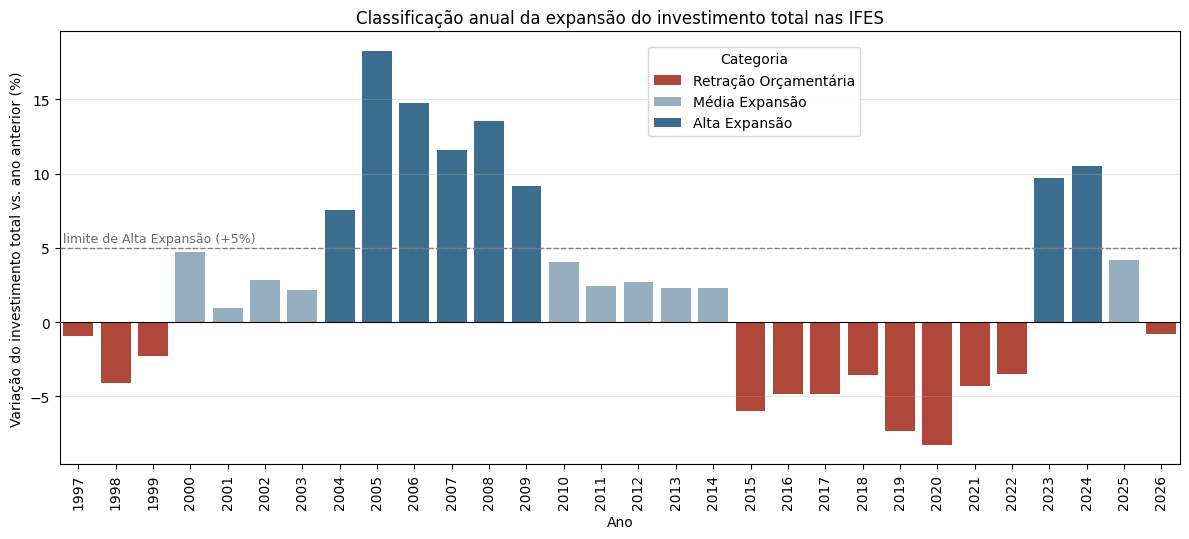

In [8]:
dados = df.dropna(subset=['categoria'])

plt.figure(figsize=(12, 5.5))
ax = sb.barplot(
    data=dados, x='ano', y='var_investimento_pct',
    hue='categoria', hue_order=ORDEM, palette=PALETA, dodge=False
)

ax.axhline(0, color='black', linewidth=0.8)
ax.axhline(5, color='gray', linewidth=1, linestyle='--')
ax.text(-0.4, 5.4, 'limite de Alta Expansão (+5%)', ha='left', fontsize=9, color='dimgray')

ax.set_title('Classificação anual da expansão do investimento total nas IFES')
ax.set_xlabel('Ano')
ax.set_ylabel('Variação do investimento total vs. ano anterior (%)')
ax.tick_params(axis='x', rotation=90)
ax.grid(axis='y', alpha=0.3)
ax.legend(title='Categoria', loc='upper center', bbox_to_anchor=(0.62, 0.98))

plt.tight_layout()
plt.show()

**O fato.** Dos 30 anos classificados, 12 foram de Retração Orçamentária, 10 de Média Expansão e 8 de Alta Expansão. A Alta Expansão se concentra em 2004-2009 (seis anos seguidos) e em 2023-2024. A retração aparece em 1997-1999, em 2015-2022 (oito anos seguidos, a sequência mais longa da série) e em 2026.

**O design.** As categorias têm um ponto de virada natural (o zero), então usei uma **paleta divergente** do seaborn: o matiz indica a direção (vermelho para retração, azul para expansão) e a intensidade do azul indica a força da expansão. Assim o leitor associa a cor ao fenômeno sem depender da legenda. Uma paleta qualitativa trataria as categorias como equivalentes, e uma sequencial esconderia a diferença entre crescer e encolher. O **gráfico de barras** com linha de base em zero deixa o sinal evidente, a **linha tracejada em +5%** mostra o limite da Alta Expansão, e a **legenda** lista as categorias na ordem natural (retração, média, alta).

## Síntese

Entre 1996 e 2014 o investimento total, a assistência estudantil e as vagas cresceram juntos. Desde 2015 as trajetórias se separaram: o investimento total caiu até 2022 e se recuperou só parcialmente depois, a assistência por vaga ficou abaixo do pico de 2011-2014, e as vagas continuaram crescendo, num ritmo muito menor. A expansão também ficou desequilibrada na força de trabalho: o número de estudantes por docente variou pouco, enquanto o de estudantes por TAE quase triplicou.